<a href="https://colab.research.google.com/github/SauleRub/BudgetTracker/blob/main/Week19/Day2/brazilian_ecommerce_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv


In [2]:
import pandas as pd
import numpy as np

# Load each uploaded CSV
df_olist_customers = pd.read_csv('olist_customers_dataset.csv')
df_olist_orders = pd.read_csv('olist_orders_dataset.csv')
df_olist_order_items = pd.read_csv('olist_order_items_dataset.csv')
df_olist_order_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
df_olist_order_payments = pd.read_csv('olist_order_payments_dataset.csv')
df_olist_sellers = pd.read_csv('olist_sellers_dataset.csv')
df_olist_products = pd.read_csv('olist_products_dataset.csv')
df_olist_geolocation = pd.read_csv('olist_geolocation_dataset.csv')
df_product_category_name_translation = pd.read_csv('product_category_name_translation.csv')

In [3]:
from sqlalchemy import create_engine

# Create the SQLite engine
engine = create_engine('sqlite:///brazil_ecommerce.db', echo=False)

# Export each DataFrame to the database
df_olist_customers.to_sql("olist_customers", con=engine, index=False)
df_olist_orders.to_sql("olist_orders", con=engine, index=False)
df_olist_order_items.to_sql("olist_order_items", con=engine, index=False)
df_olist_order_reviews.to_sql("olist_order_reviews", con=engine, index=False)
df_olist_order_payments.to_sql("olist_order_payments", con=engine, index=False)
df_olist_sellers.to_sql("olist_sellers", con=engine, index=False)
df_olist_products.to_sql("olist_products_dataset", con=engine, index=False)
df_olist_geolocation.to_sql("olist_geolocation", con=engine, index=False)
df_product_category_name_translation.to_sql("product_category_name_translation", con=engine, index=False)

71

In [4]:
sql = '''
SELECT * FROM olist_customers
LIMIT 5;
'''

df_sql = pd.read_sql_query(sql, con=engine)
df_sql.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
sql = '''
WITH jan_orders AS (
  SELECT o.order_id, r.review_score
  FROM olist_orders o
  JOIN olist_order_reviews r
    ON o.order_id = r.order_id
  WHERE o.order_purchase_timestamp LIKE '2018-01%'
)

SELECT
  COUNT(*) AS total_jan_orders,
  SUM(CASE WHEN review_score = 5 THEN 1 ELSE 0 END) AS five_star_orders,
  ROUND(
    SUM(CASE WHEN review_score = 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(*),
    2
  ) AS five_star_percentage
FROM jan_orders;
'''

df_query1 = pd.read_sql_query(sql, con=engine)
df_query1

,total_jan_orders,five_star_orders,five_star_percentage
0,7245,4097,56.55


Over half (56.55%) of the orders in January 2018 received a perfect review score of 5 — this suggests a generally positive customer experience during that month. This could indicate:

	•	Effective delivery performance
  
	•	High customer satisfaction

	•	Successful post-holiday operations

In [6]:
sql = '''
SELECT
  STRFTIME('%Y', order_purchase_timestamp) AS year,
  COUNT(DISTINCT customer_id) AS unique_customers
FROM olist_orders
GROUP BY year
ORDER BY year;
'''

df_query2 = pd.read_sql_query(sql, con=engine)
df_query2

,year,unique_customers
0,2016,329
1,2017,45101
2,2018,54011


Interpretation:

	•	Explosive growth from 2016 → 2017: from 329 to 45,101 customers — this likely reflects the platform’s official launch or early scaling.

	•	Continued growth into 2018 with ~20% YoY increase (from 45K → 54K).

This suggests:

	•	The e-commerce platform saw rapid customer adoption
	•	Possibly benefited from aggressive marketing, logistics improvement, or word-of-mouth

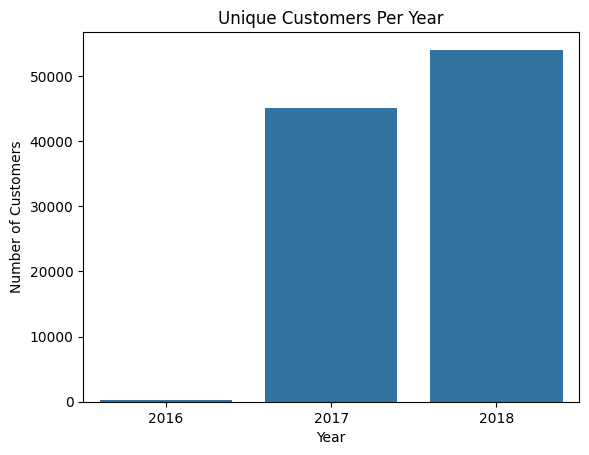

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df_query2, x='year', y='unique_customers')
plt.title('Unique Customers Per Year')
plt.ylabel('Number of Customers')
plt.xlabel('Year')
plt.show()

In [8]:
sql = '''
SELECT
  ROUND(AVG(payment_value), 2) AS avg_order_value
FROM olist_order_payments;
'''

df_query3 = pd.read_sql_query(sql, con=engine)
df_query3

,avg_order_value
0,154.1


In [9]:
sql = '''
SELECT
  ROUND(AVG(order_total), 2) AS avg_order_value_per_customer
FROM (
  SELECT
    o.customer_id,
    SUM(p.payment_value) AS order_total
  FROM olist_orders o
  JOIN olist_order_payments p ON o.order_id = p.order_id
  GROUP BY o.customer_id
);
'''
df_query3 = pd.read_sql_query(sql, con=engine)
df_query3

,avg_order_value_per_customer
0,160.99


Interpretation:

	•	Each order brings ~R$154 on average.

	•	Each customer contributes slightly more (R$161), suggesting:

      	•	Some customers make multiple purchases

	    •	Or pay for higher-value items over time


These metrics are key for business strategy, especially for:

	•	Estimating revenue per user (ARPU)

	•	Setting marketing budget per acquisition
  
	•	Forecasting growth

In [10]:
sql = '''
SELECT
  c.customer_city,
  ROUND(SUM(p.payment_value), 2) AS total_revenue
FROM olist_orders o
JOIN olist_customers c ON o.customer_id = c.customer_id
JOIN olist_order_payments p ON o.order_id = p.order_id
WHERE STRFTIME('%Y', o.order_purchase_timestamp) BETWEEN '2016' AND '2018'
GROUP BY c.customer_city
ORDER BY total_revenue DESC
LIMIT 5;
'''

df_query4 = pd.read_sql_query(sql, con=engine)
df_query4

,customer_city,total_revenue
0,sao paulo,2203373.09
1,rio de janeiro,1161927.36
2,belo horizonte,421765.12
3,brasilia,354216.78
4,curitiba,247392.48


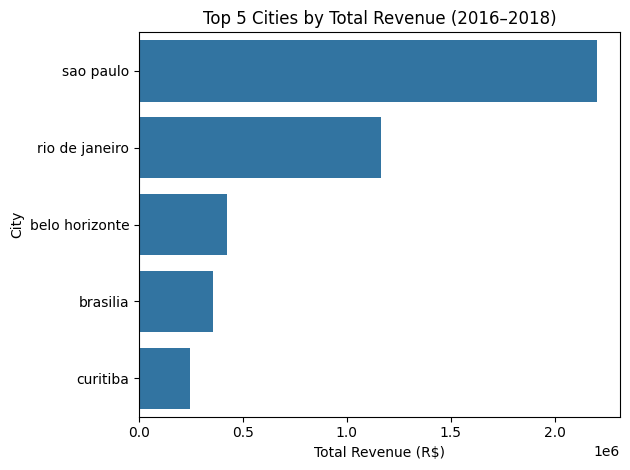

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df_query4, x='total_revenue', y='customer_city')
plt.title('Top 5 Cities by Total Revenue (2016–2018)')
plt.xlabel('Total Revenue (R$)')
plt.ylabel('City')
plt.tight_layout()
plt.show()

Insights:

	•	São Paulo alone generated nearly double the revenue of the second-highest city, Rio.

	•	There’s a steep revenue drop from 2nd → 3rd place → indicates market concentration in top cities.
  
	•	The top cities are all southeastern urban centers, reflecting digital adoption and infrastructure.


In [12]:
sql = '''
SELECT
  c.customer_state,
  ROUND(SUM(p.payment_value), 2) AS total_revenue
FROM olist_orders o
JOIN olist_customers c ON o.customer_id = c.customer_id
JOIN olist_order_payments p ON o.order_id = p.order_id
WHERE STRFTIME('%Y', o.order_purchase_timestamp) BETWEEN '2016' AND '2018'
GROUP BY c.customer_state
ORDER BY total_revenue DESC;
'''

df_query5 = pd.read_sql_query(sql, con=engine)
df_query5

,customer_state,total_revenue
0,SP,5998226.96
1,RJ,2144379.69
2,MG,1872257.26
3,RS,890898.54
4,PR,811156.38
5,SC,623086.43
6,BA,616645.82
7,DF,355141.08
8,GO,350092.31
9,ES,325967.55


Insights:

	•	São Paulo dominates, with more than double the revenue of Rio de Janeiro.

	•	Top 3 states (SP, RJ, MG) together account for the majority of total revenue → strong concentration in the Southeast.

	•	Northern states (e.g., Roraima, Amapá, Acre) generate tiny fractions of revenue — possibly due to:

	    •	Smaller population

	    •	Less developed logistics infrastructure

	    •	Lower e-commerce penetration


/tmp/ipython-input-2103049337.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_query5, x='total_revenue', y='customer_state', palette='viridis')


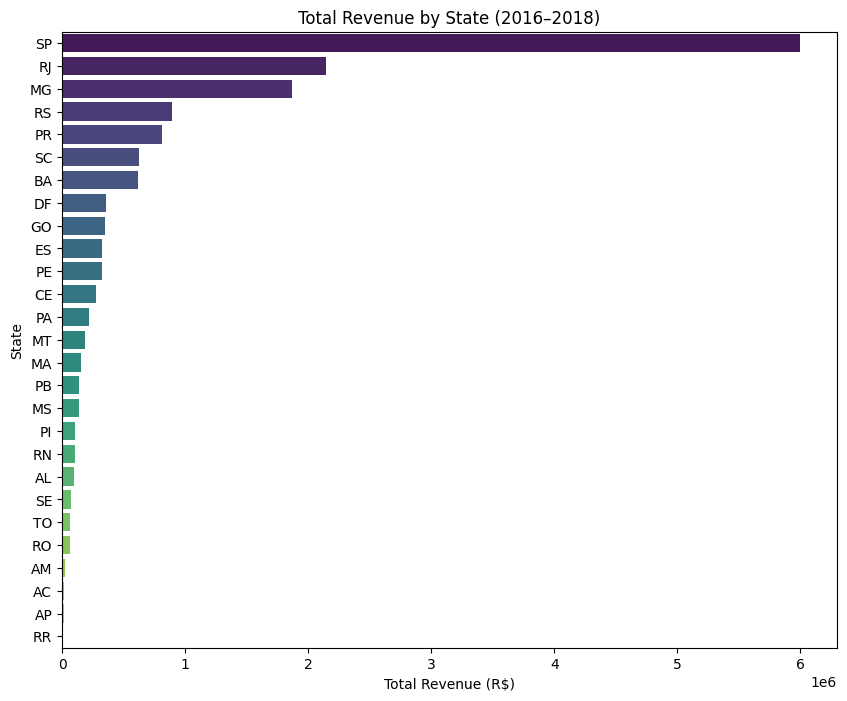

In [13]:
plt.figure(figsize=(10,8))
sns.barplot(data=df_query5, x='total_revenue', y='customer_state', palette='viridis')
plt.title('Total Revenue by State (2016–2018)')
plt.xlabel('Total Revenue (R$)')
plt.ylabel('State')
plt.show()

In [14]:
sql = '''
WITH seller_metrics AS (
  SELECT
    i.seller_id,
    COUNT(i.order_item_id) AS total_items_sold,
    ROUND(SUM(p.payment_value), 2) AS total_revenue,
    COUNT(DISTINCT o.customer_id) AS unique_customers
  FROM olist_order_items i
  JOIN olist_orders o ON i.order_id = o.order_id
  JOIN olist_order_payments p ON o.order_id = p.order_id
  GROUP BY i.seller_id
)

SELECT *
FROM seller_metrics
ORDER BY total_revenue DESC
LIMIT 10;
'''

df_query6 = pd.read_sql_query(sql, con=engine)
df_query6

,seller_id,total_items_sold,total_revenue,unique_customers
0,7c67e1448b00f6e969d365cea6b010ab,1452,507166.91,982
1,1025f0e2d44d7041d6cf58b6550e0bfa,1462,308222.04,915
2,4a3ca9315b744ce9f8e9374361493884,2133,301245.27,1806
3,1f50f920176fa81dab994f9023523100,2008,290253.42,1404
4,53243585a1d6dc2643021fd1853d8905,437,284903.08,358
5,da8622b14eb17ae2831f4ac5b9dab84a,1639,272219.32,1314
6,4869f7a5dfa277a7dca6462dcf3b52b2,1186,264166.12,1132
7,955fee9216a65b617aa5c0531780ce60,1528,236322.30,1287
8,fa1c13f2614d7b5c4749cbc52fecda94,609,206513.23,585
9,7e93a43ef30c4f03f38b393420bc753a,352,185134.21,336


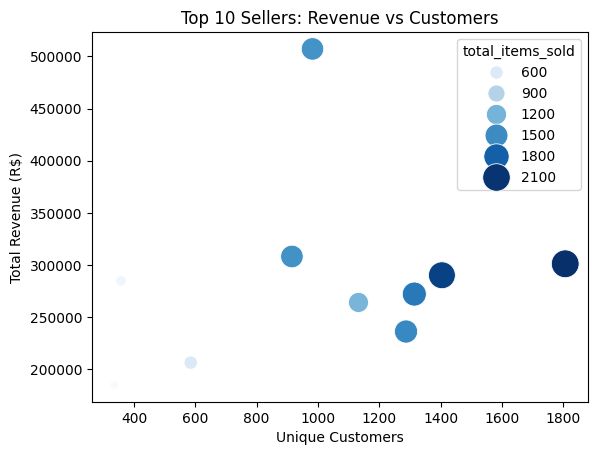

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df_query6, x='unique_customers', y='total_revenue', size='total_items_sold', hue='total_items_sold', palette='Blues', sizes=(40, 400))
plt.title('Top 10 Sellers: Revenue vs Customers')
plt.xlabel('Unique Customers')
plt.ylabel('Total Revenue (R$)')
plt.show()

In [16]:
sql = '''
WITH state_delivery_stats AS (
  SELECT
    c.customer_state,
    COUNT(*) AS total_orders,
    SUM(CASE WHEN o.order_status = 'delivered' THEN 1 ELSE 0 END) AS delivered_orders
  FROM olist_orders o
  JOIN olist_customers c ON o.customer_id = c.customer_id
  GROUP BY c.customer_state
)

SELECT
  customer_state,
  total_orders,
  delivered_orders,
  ROUND(delivered_orders * 100.0 / total_orders, 2) AS delivery_success_rate
FROM state_delivery_stats
ORDER BY delivery_success_rate DESC;
'''

df_query7 = pd.read_sql_query(sql, con=engine)
df_query7

,customer_state,total_orders,delivered_orders,delivery_success_rate
0,AC,81,80,98.77
1,AP,68,67,98.53
2,ES,2033,1995,98.13
3,MS,715,701,98.04
4,AM,148,145,97.97
5,TO,280,274,97.86
6,RS,5466,5345,97.79
7,RN,485,474,97.73
8,MT,907,886,97.68
9,MG,11635,11354,97.58


Insights:

	•	Most states show very high delivery success rates (97–98%) → Brazil’s logistics seem robust in urban areas.

	•	RR (Roraima) has a significantly lower rate (89.13%) — likely due to:

	    •	Remote Amazon location

        •	Poor infrastructure

        •	Weather or geographic access

This is critical for:

	•	Targeting logistics improvement

	•	Regional expansion planning
  
	•	Customer satisfaction tracking

/tmp/ipython-input-339400545.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_query7, x='delivery_success_rate', y='customer_state', palette='coolwarm')


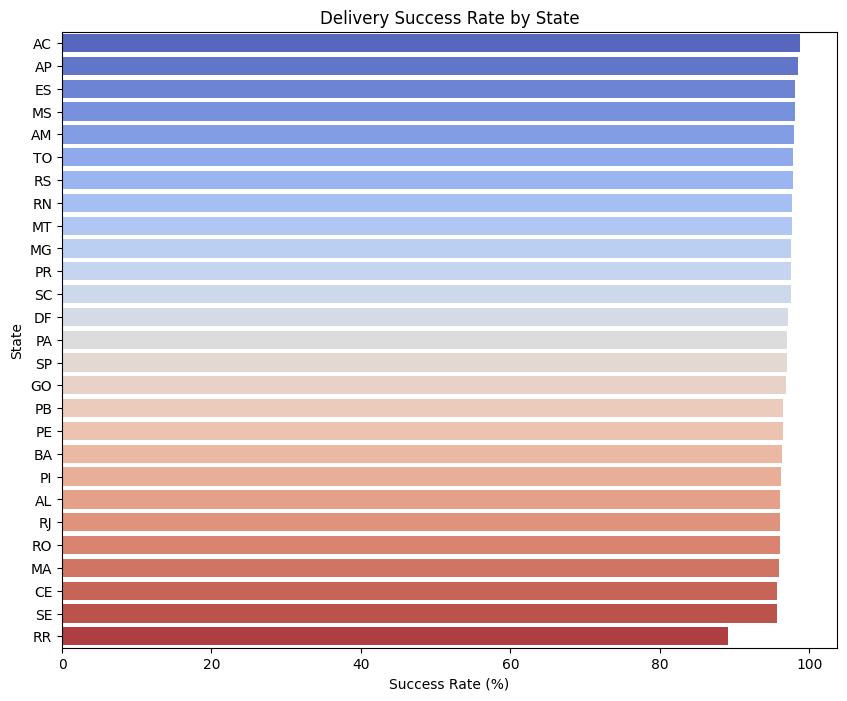

In [17]:
plt.figure(figsize=(10, 8))
sns.barplot(data=df_query7, x='delivery_success_rate', y='customer_state', palette='coolwarm')
plt.title('Delivery Success Rate by State')
plt.xlabel('Success Rate (%)')
plt.ylabel('State')
plt.show()

In [18]:
sql = '''
WITH payment_category_counts AS (
  SELECT
    p.payment_type,
    pr.product_category_name,
    COUNT(*) AS payment_count
  FROM olist_order_payments p
  JOIN olist_orders o ON p.order_id = o.order_id
  JOIN olist_order_items i ON o.order_id = i.order_id
  JOIN olist_products_dataset pr ON i.product_id = pr.product_id
  GROUP BY pr.product_category_name, p.payment_type
)

SELECT
  product_category_name,
  payment_type,
  payment_count
FROM (
  SELECT *,
    ROW_NUMBER() OVER(PARTITION BY product_category_name ORDER BY payment_count DESC) AS rn
  FROM payment_category_counts
)
WHERE rn = 1
ORDER BY payment_count DESC;
'''

df_query8 = pd.read_sql_query(sql, con=engine)
df_query8

,product_category_name,payment_type,payment_count
0,cama_mesa_banho,credit_card,8959
1,beleza_saude,credit_card,7566
2,esporte_lazer,credit_card,6635
3,moveis_decoracao,credit_card,6379
4,informatica_acessorios,credit_card,5436
...,...,...,...
69,cds_dvds_musicais,credit_card,9
70,portateis_cozinha_e_preparadores_de_alimentos,credit_card,8
71,fashion_roupa_infanto_juvenil,credit_card,5
72,pc_gamer,credit_card,5


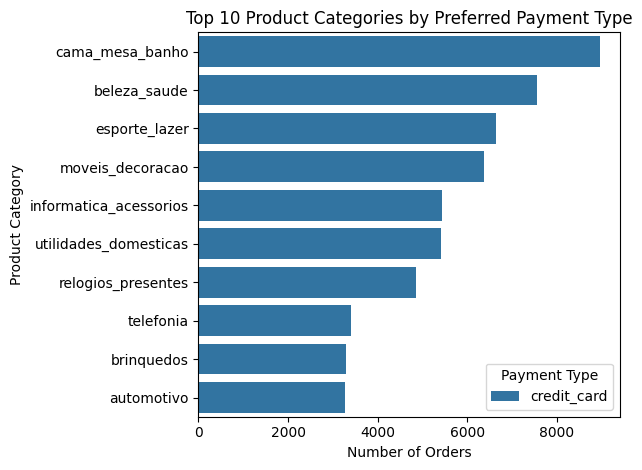

In [19]:
top10 = df_query8.head(10)

sns.barplot(data=top10, x='payment_count', y='product_category_name', hue='payment_type')
plt.title('Top 10 Product Categories by Preferred Payment Type')
plt.xlabel('Number of Orders')
plt.ylabel('Product Category')
plt.legend(title='Payment Type')
plt.tight_layout()
plt.show()

Insight Summary:

	•	Credit cards dominate nearly all categories — consistent with consumer habits in Brazil.

	•	Categories like cama_mesa_banho, beleza_saude, and esporte_lazer are high-volume and almost exclusively card-driven.

	•	Only one category (seguros_e_servicos) has boleto as top — possibly due to specific payment handling in services or insurance.

This is valuable for:

	•	Payment optimization

	•	Fraud risk modeling
  
	•	Checkout UX tailoring

In [20]:
# Average lat/lng per zip code prefix
df_geo = df_olist_geolocation.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean'
}).reset_index()

# Rename for clarity
df_geo.columns = ['zip_code_prefix', 'lat', 'lng']

In [21]:
# 1. Merge customer location
df_orders_customers = df_olist_orders.merge(df_olist_customers, on='customer_id')
df_orders_customers['customer_zip'] = df_orders_customers['customer_zip_code_prefix']

# 2. Merge seller location
df_order_sellers = df_olist_order_items.merge(df_olist_sellers, on='seller_id')
df_order_sellers['seller_zip'] = df_order_sellers['seller_zip_code_prefix']

# 3. Merge orders and sellers
df_order_locations = df_orders_customers[['order_id', 'customer_zip']].merge(
    df_order_sellers[['order_id', 'seller_zip']], on='order_id')

# 4. Merge lat/lng for customer
df_order_locations = df_order_locations.merge(df_geo, left_on='customer_zip', right_on='zip_code_prefix')
df_order_locations.rename(columns={'lat': 'cust_lat', 'lng': 'cust_lng'}, inplace=True)

# 5. Merge lat/lng for seller
df_order_locations = df_order_locations.merge(df_geo, left_on='seller_zip', right_on='zip_code_prefix')
df_order_locations.rename(columns={'lat': 'seller_lat', 'lng': 'seller_lng'}, inplace=True)

In [22]:
import numpy as np

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

In [23]:
# Compute distance
df_order_locations['distance_km'] = haversine(
    df_order_locations['cust_lat'],
    df_order_locations['cust_lng'],
    df_order_locations['seller_lat'],
    df_order_locations['seller_lng']
)

# Drop any missing coords
df_order_locations.dropna(subset=['distance_km'], inplace=True)

# Compute average
average_distance = df_order_locations['distance_km'].mean()
print(f'📏 Average shipping distance per order: {average_distance:.2f} km')

📏 Average shipping distance per order: 596.96 km


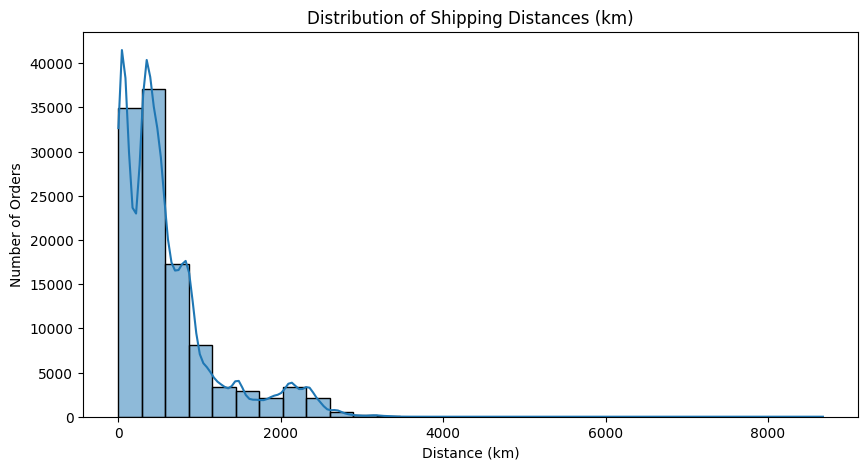

In [24]:
plt.figure(figsize=(10,5))
sns.histplot(df_order_locations['distance_km'], bins=30, kde=True)
plt.title('Distribution of Shipping Distances (km)')
plt.xlabel('Distance (km)')
plt.ylabel('Number of Orders')
plt.show()